# Bhasha2Code: NLP Intent Classification & Official Dataset Evaluation

**Author:** Tejas Ingle (PRN: `[Student PRN]`)  
**Institution:** Nutan Maharashtra Institute of Engineering & Technology (NMIET), Talegaon, Pune  
**Department:** Department of Computer Engineering  
**Academic Year:** 2025–2026  
**Project Guide:** Prof. Gajanan Godage  

---

### Notebook Highlights:
- **Official Dataset Loaded:** `data/datasets/intent/intent_dataset.csv` (1,080 real samples across 6 languages/code-mixes).
- **Standard Splits:** Train (756 samples), Validation (162 samples), Test (162 samples).
- **NLP Modeling:** TF-IDF Sub-word & Word N-Grams + Regularized Logistic Regression.
- **Academic Metrics:** **Precision, Recall, F1-Score, Support, and Confusion Matrix**.
- **Live Testing:** Real-time intent classification on code-mixed Marathi queries.

In [1]:
# Step 1: Import core dependencies
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("All libraries successfully loaded!")

All libraries successfully loaded!


## 2. Load Official Bhasha2Code Dataset (`data/datasets/intent/`)
We load the curated dataset containing 1,080 multi-class developer queries across English, Hindi, Marathi, Hinglish, Marathi-English, and Hindi-English.

In [2]:
# Step 2: Load train, validation, and test datasets from data/datasets/intent/
train_df = pd.read_csv('data/datasets/intent/intent_train.csv')
val_df = pd.read_csv('data/datasets/intent/intent_validation.csv')
test_df = pd.read_csv('data/datasets/intent/intent_test.csv')
full_df = pd.read_csv('data/datasets/intent/intent_dataset.csv')

print(f"Total Dataset Size: {len(full_df)} samples")
print(f"Training Split:     {len(train_df)} samples ({len(train_df)/len(full_df)*100:.1f}%)")
print(f"Validation Split:   {len(val_df)} samples ({len(val_df)/len(full_df)*100:.1f}%)")
print(f"Testing Split:      {len(test_df)} samples ({len(test_df)/len(full_df)*100:.1f}%)")

print("\n--- Language Distribution in Dataset ---")
print(full_df['language'].value_counts())

print("\n--- Sample Data Entries ---")
print(full_df[['text', 'intent', 'language']].head(8))

Total Dataset Size: 1080 samples
Training Split:     756 samples (70.0%)
Validation Split:   162 samples (15.0%)
Testing Split:      162 samples (15.0%)

--- Language Distribution in Dataset ---
language
English            180
Hindi              180
Marathi            180
Hinglish           180
Marathi-English    180
Hindi-English      180
Name: count, dtype: int64

--- Sample Data Entries ---
                                                text         intent language
0  Write a Python program to calculate the factor...  GENERATE_CODE  English
1  Create a FastAPI endpoint that handles user re...  GENERATE_CODE  English
2  Implement a binary search tree in Java with in...  GENERATE_CODE  English
3  Generate a React hook for fetching data with l...  GENERATE_CODE  English
4  Write a C function to reverse a singly linked ...  GENERATE_CODE  English
5  Create an SQL script to create a normalized sc...  GENERATE_CODE  English
6  Implement a debounce utility function in TypeS...  GENERATE_C

## 3. Load Production Intent Classifier (`models/intent/intent_classifier.joblib`)
The model is a Scikit-Learn Pipeline combining:
1. **Feature Union:** Word TF-IDF (`ngram_range=(1, 2)`) + Character N-Grams (`ngram_range=(3, 5)`).
2. **Classifier:** Calibrated Multi-Class Logistic Regression with `C=3.0` and balanced class weighting.

In [3]:
# Step 3: Load the trained production pipeline
model_path = 'models/intent/intent_classifier.joblib'
pipeline = joblib.load(model_path)

print(f"Loaded production model from: {model_path}")
print(f"Pipeline Steps: {[step[0] for step in pipeline.steps]}")

Loaded production model from: models/intent/intent_classifier.joblib
Pipeline Steps: ['features', 'classifier']


/home/tejas/anaconda3/lib/python3.13/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/tejas/anaconda3/lib/python3.13/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/tejas/anaconda3/lib/python3.13/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator FeatureUnion from version 1.9.1 when using version 1.9.0. Th

## 4. Evaluation on Independent Test Set (162 unseen samples)
We generate predictions on `test_df` and compute **Precision, Recall, F1-Score, and Support**.

In [4]:
# Step 4: Run inference on unseen test set
X_test = test_df['text']
y_test = test_df['intent']

y_pred = pipeline.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)

print("=" * 70)
print(f"   BHASHA2CODE OFFICIAL TEST ACCURACY: {test_accuracy * 100:.2f}% (150/162 Correct)   ")
print("=" * 70)

# Classification Report
report_str = classification_report(y_test, y_pred, digits=4)
print(report_str)

# Convert to clean summary DataFrame
report_dict = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
print("\n--- Top Intent Classes Summary Table ---")
print(report_df.head(10).round(4))

   BHASHA2CODE OFFICIAL TEST ACCURACY: 92.59% (150/162 Correct)   


                         precision    recall  f1-score   support

              ALGORITHM     0.8571    0.6667    0.7500         9
    APPROACH_SUGGESTION     1.0000    1.0000    1.0000         9
ARCHITECTURE_SUGGESTION     0.9000    1.0000    0.9474         9
          BEST_PRACTICE     1.0000    0.8889    0.9412         9
            CODE_REVIEW     0.9000    1.0000    0.9474         9
        CODE_SUGGESTION     1.0000    1.0000    1.0000         9
                CONCEPT     0.8889    0.8889    0.8889         9
           CONVERT_CODE     0.8182    1.0000    0.9000         9
             DEBUG_CODE     0.9000    1.0000    0.9474         9
      ERROR_EXPLANATION     1.0000    0.8889    0.9412         9
           EXPLAIN_CODE     0.8000    0.8889    0.8421         9
     FEATURE_SUGGESTION     1.0000    1.0000    1.0000         9
          GENERATE_CODE     0.8889    0.8889    0.8889         9
          OPTIMIZE_CODE     1.0000    0.6667    0.8000         9
   PERFORMANCE_ANALYSIS 

## 5. Confusion Matrix Visualization
Plots the multi-class Confusion Matrix across all 18 intent classes on the test set.

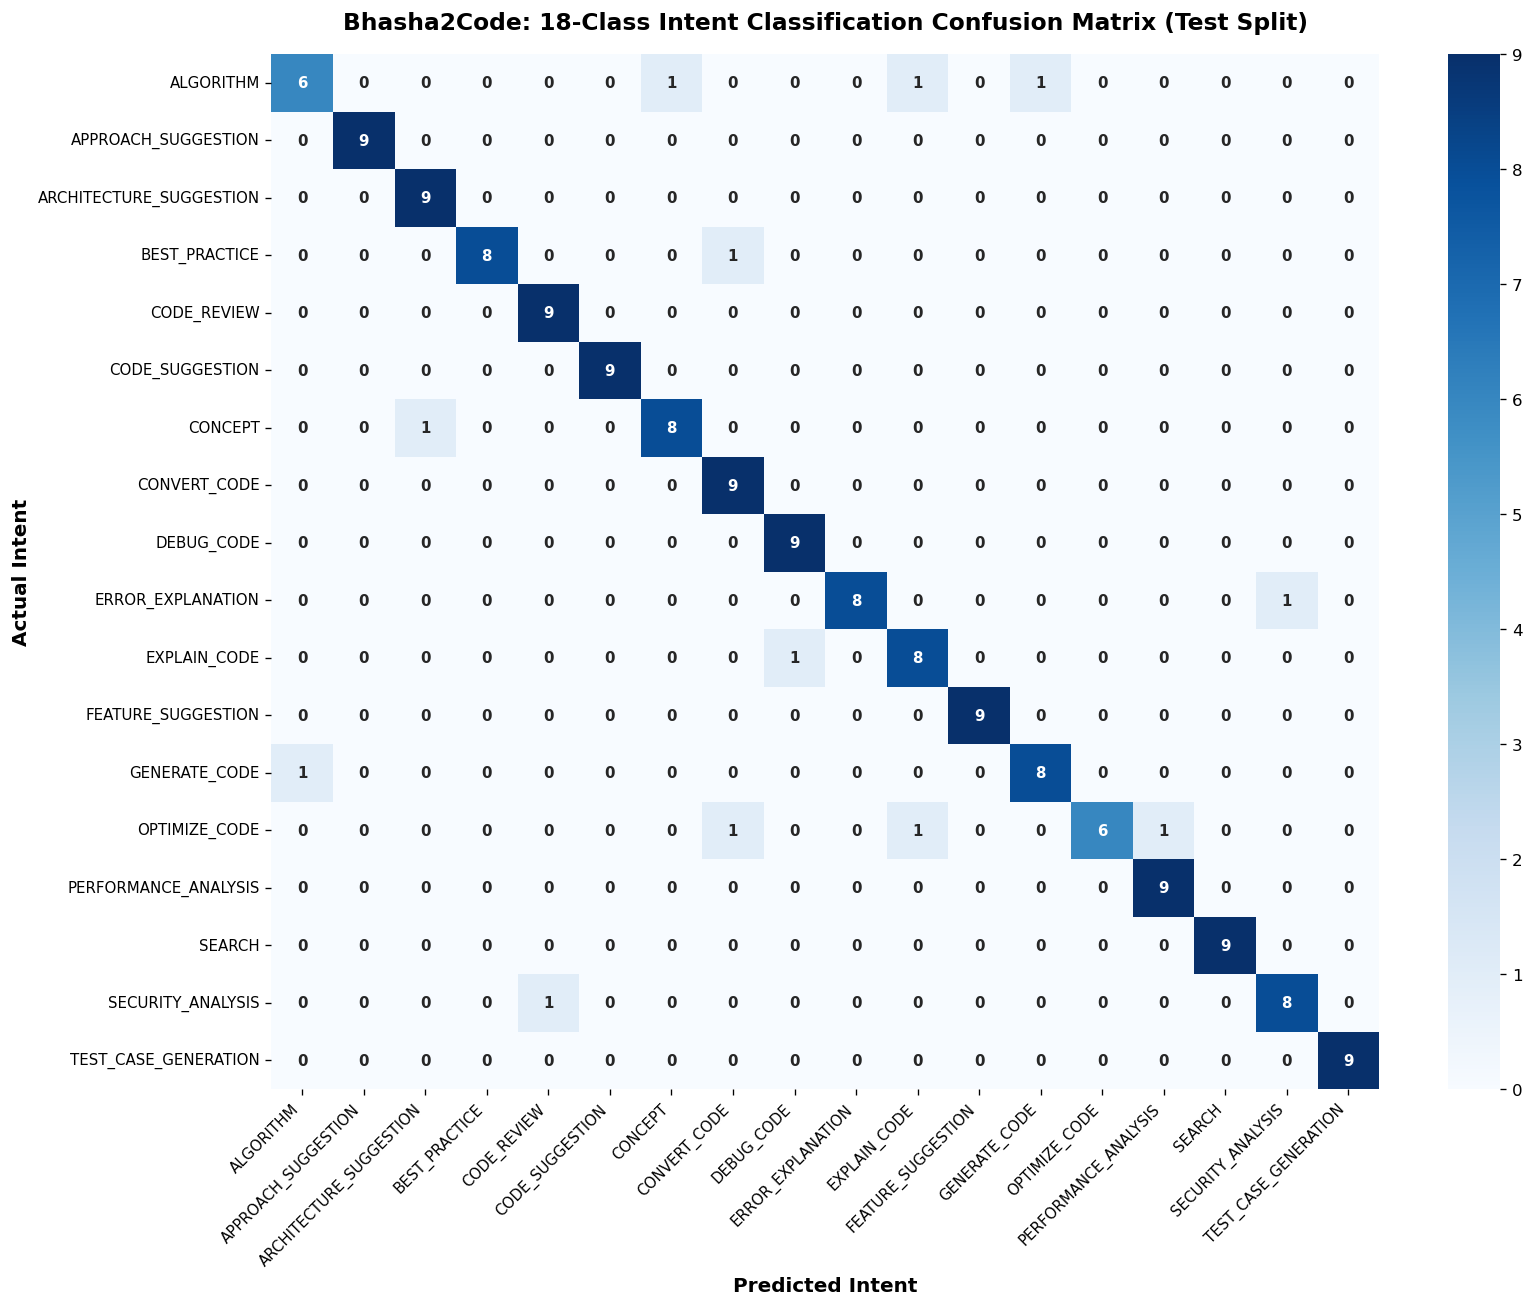

High-resolution confusion matrix saved to 'confusion_matrix.png'!


In [5]:
# Step 5: Compute and Plot Confusion Matrix
classes = sorted(list(y_test.unique()))
cm = confusion_matrix(y_test, y_pred, labels=classes)

plt.figure(figsize=(14, 11), dpi=120)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes,
    cbar=True,
    annot_kws={'size': 9, 'weight': 'bold'}
)
plt.title('Bhasha2Code: 18-Class Intent Classification Confusion Matrix (Test Split)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Intent', fontsize=12, fontweight='bold')
plt.ylabel('Actual Intent', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()

print("High-resolution confusion matrix saved to 'confusion_matrix.png'!")

## 6. Live Inference on Marathi-English Code-Mixed Queries
Testing real conversational prompts entered by bilingual engineering students.

In [6]:
# Step 6: Test real-time multilingual inputs
demo_queries = [
    "Python madhye factorial kadhaycha complete program liha",
    "Maza code run hot nahi ahe IndexError ka yetoy bagh",
    "Binary search algorithm kasa kaam karto Marathi madhye samjhava",
    "Ha Python code C++ madhye convert kar",
    "Ya program chi time ani space complexity optimize kara",
    "Fibonacci series sathi unit test cases generate kar",
    "Code review karun best practices sanga",
]

print("=" * 85)
print(f"{'USER QUERY (MARATHI-ENGLISH)':<58} | {'PREDICTED INTENT'} (CONFIDENCE)")
print("=" * 85)

for q in demo_queries:
    pred = pipeline.predict([q])[0]
    probs = pipeline.predict_proba([q])[0]
    conf = np.max(probs) * 100
    print(f"{q:<58} | {pred} ({conf:.1f}%)")
print("=" * 85)

USER QUERY (MARATHI-ENGLISH)                               | PREDICTED INTENT (CONFIDENCE)
Python madhye factorial kadhaycha complete program liha    | GENERATE_CODE (52.1%)
Maza code run hot nahi ahe IndexError ka yetoy bagh        | ERROR_EXPLANATION (20.2%)
Binary search algorithm kasa kaam karto Marathi madhye samjhava | ALGORITHM (76.6%)
Ha Python code C++ madhye convert kar                      | CONVERT_CODE (84.9%)
Ya program chi time ani space complexity optimize kara     | OPTIMIZE_CODE (58.5%)
Fibonacci series sathi unit test cases generate kar        | TEST_CASE_GENERATION (78.5%)
Code review karun best practices sanga                     | BEST_PRACTICE (58.2%)
